In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv("powerplant_data.csv")

In [3]:
df.head()

,AT,V,AP,RH,PE
0,8.34,40.77,1010.84,90.01,480.48
1,23.64,58.49,1011.40,74.20,445.75
2,29.74,56.90,1007.15,41.91,438.76
3,19.07,49.69,1007.22,76.79,453.09
4,11.80,40.66,1017.13,97.20,464.43


In [4]:
# AT=> Temprature
# V => Vaccum
# AP => Pressure
# RH => Humidity

# PE => Produced energy


In [5]:
df.isnull().sum()

AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64

In [6]:
X = df.drop("PE", axis=1)
y = df["PE"]

In [7]:
X

,AT,V,AP,RH
0,8.34,40.77,1010.84,90.01
1,23.64,58.49,1011.40,74.20
2,29.74,56.90,1007.15,41.91
3,19.07,49.69,1007.22,76.79
4,11.80,40.66,1017.13,97.20
...,...,...,...,...
9563,15.12,48.92,1011.80,72.93
9564,33.41,77.95,1010.30,59.72
9565,15.99,43.34,1014.20,78.66
9566,17.65,59.87,1018.58,94.65


In [8]:
y

0       480.48
1       445.75
2       438.76
3       453.09
4       464.43
         ...  
9563    462.59
9564    432.90
9565    465.96
9566    450.93
9567    451.67
Name: PE, Length: 9568, dtype: float64

In [9]:
# Split out data

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [10]:
df.shape

(9568, 5)

In [11]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.fit_transform(X_test)

In [12]:
X_train_scaled

array([[ 0.74805289,  0.72006931, -0.32660017, -0.49711722],
       [ 0.86181948,  1.26515721, -0.98521113,  0.8181501 ],
       [ 0.93409473,  1.52314975,  0.32523844,  0.80167494],
       ...,
       [-0.22097078, -0.834965  ,  0.36756563, -0.83554456],
       [ 0.94747903,  1.14245344, -0.41971997, -0.45455637],
       [-1.77355014, -1.19049131,  1.92520594,  0.91837402]],
      shape=(7654, 4))

In [13]:
X_test_scaled

array([[ 1.36255441,  0.24305848, -1.27798491, -1.04586379],
       [ 0.82147733,  1.36986442, -0.74695303,  0.31071896],
       [-0.247116  , -0.73708132,  1.92304887, -0.14668594],
       ...,
       [-0.67970645, -1.15815506, -0.31652036, -0.05697206],
       [ 1.33136451,  1.34463153, -0.87558808, -0.39000089],
       [-0.26474508, -0.26711887,  0.33984824,  1.14397069]],
      shape=(1914, 4))

In [14]:
# converting data into tensors

import torch
import torch.nn as nn

X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32).view(-1,1)

X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float32).view(-1,1)

In [15]:
# tensordataset and dataloader

from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

In [16]:
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32)

### Deep Learning



In [17]:
# Define ANN Model

class ANN(nn.Module):
    def __init__(self):
        super(ANN, self).__init__()

        self.model = nn.Sequential(
            # 1st hidden layer
            nn.Linear(X_train.shape[1], 6),
            nn.ReLU(),
    
            # 2nd hidden layer
            nn.Linear(6, 6),
            nn.ReLU(),
    
            # output layer
            nn.Linear(6,1)
            
        )

    def forward(self,x):
        return self.model(x)

In [18]:
import torch.optim as optim

model = ANN()

# loss, optimiser
crietrion = nn.MSELoss()

optimizer = optim.Adam(model.parameters())

In [19]:
# train ANN model

train_losses = []
val_losses = []

best_val_loss = float("inf")

epochs = 100

for epoch in range(epochs):
    model.train()
    running_loss = 0.0 # total training los for 1 epoch

    for xb, yb in train_loader:
        # xb = features of 1 batch
        # yb = labels of 1 batch
        
        optimizer.zero_grad()
        
        outputs = model(xb) # forward prop.... predicted outputs for this batch
        loss = crietrion(outputs, yb) #compute loss
        loss.backward() # back prop... compute gradients
        optimizer.step() # params update

        running_loss +=loss.item() # loss is tensor => py float

    epoch_train_loss = running_loss / len(train_loader)
    train_losses.append(epoch_train_loss)

    
    # validation
    model.eval()
    running_val_loss = 0.0

    with torch.no_grad(): # no gradients compute
        for xb, yb in test_loader:
            outputs = model(xb)
            loss = crietrion(outputs, yb)
            running_val_loss +=loss

    epoch_val_loss = running_val_loss / len(test_loader)
    val_losses.append(epoch_val_loss)

    print(f"epoch {epoch+1}/{epochs} ==> train loss = {epoch_train_loss} & val loss = {epoch_val_loss}")

    if epoch_val_loss < best_val_loss:
        best_val_los = epoch_val_loss
        torch.save(model.state_dict(), "best_model.pt") # .pt or .pth
        
        
        

epoch 1/100 ==> train loss = 205453.29986979166 & val loss = 202635.0625
epoch 2/100 ==> train loss = 193214.61712239584 & val loss = 178356.109375
epoch 3/100 ==> train loss = 153514.02278645834 & val loss = 123966.5
epoch 4/100 ==> train loss = 92800.73927408854 & val loss = 63049.078125
epoch 5/100 ==> train loss = 44214.66930338542 & val loss = 29741.783203125
epoch 6/100 ==> train loss = 24944.538529459634 & val loss = 20319.5625
epoch 7/100 ==> train loss = 19273.683015950523 & val loss = 16522.80078125
epoch 8/100 ==> train loss = 15626.272237141928 & val loss = 13167.736328125
epoch 9/100 ==> train loss = 12193.972546386718 & val loss = 9973.9599609375
epoch 10/100 ==> train loss = 8965.595520019531 & val loss = 7102.6484375
epoch 11/100 ==> train loss = 6170.407262166341 & val loss = 4746.3310546875
epoch 12/100 ==> train loss = 4034.216057840983 & val loss = 3078.8251953125
epoch 13/100 ==> train loss = 2603.5940198262533 & val loss = 2004.9471435546875
epoch 14/100 ==> train

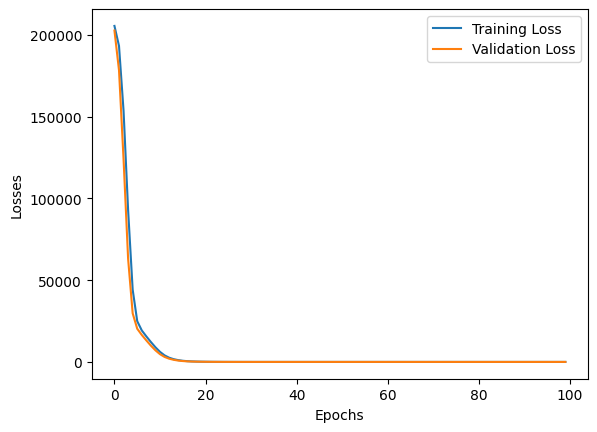

In [20]:
# plot
import matplotlib.pyplot as plt

loss_df = pd.DataFrame({
    "Training Loss" :train_losses,
    "Validation Loss": val_losses
})

plt.plot(loss_df["Training Loss"], label = "Training Loss")
plt.plot(loss_df["Validation Loss"], label = "Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Losses")

plt.legend()

In [21]:
# loading the besat model

model.load_state_dict(torch.load("best_model.pt"))


<All keys matched successfully>

In [22]:
# Evaluate our model

model.eval()

with torch.no_grad():
    train_preds = model(X_train_tensor)
    test_preds = model(X_test_tensor)

    train_mse_loss = crietrion(train_preds, y_train_tensor)
    test_mse_loss = crietrion(test_preds, y_test_tensor)

print("Training MSE: ", train_mse_loss.item())
print("Testing MSE: ", test_mse_loss.item())

Training MSE:  20.775554656982422
Testing MSE:  19.399869918823242


In [24]:
from sklearn.metrics import r2_score

print("r^2 score = ",r2_score(y_test, test_preds))

r^2 score =  0.9322024631156123


In [25]:
predicted_df = pd.DataFrame(test_preds.numpy(), columns=["Predicted Values"])
actual_df = pd.DataFrame(y_test.values,columns=["Actual Values"])

pd.concat([predicted_df, actual_df],axis=1)

,Predicted Values,Actual Values
0,434.074127,433.27
1,435.834961,438.16
2,462.401337,458.42
3,477.989410,480.82
4,434.747284,441.41
...,...,...
1909,451.093292,456.70
1910,430.338196,438.04
1911,467.971924,467.80
1912,429.736847,437.14
